# Nepal vs USA: SDG 5 (Gender Equality) and SDG 9 (Industry and Infrastructure)

Cleans four public UN SDG datasets, merges them into one file for a Tableau dashboard, and tests how women's representation in parliament relates to manufacturing and other indicators.

Steps: load and filter, merge and clean, correlation analysis, findings.

Note: both series trend over time, so a strong correlation here does not show that one causes the other.

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries loaded!")

Libraries loaded!


In [17]:
usa_g5 = pd.read_excel('USA Dataset.xlsx', sheet_name='Goal5')

print(usa_g5.shape)

(986, 26)


In [18]:
# Look at all column names in the USA Goal 5 data
# This shows us what information is available in each row
print(usa_g5.columns.tolist())

['Goal', 'Target', 'Indicator', 'SeriesCode', 'SeriesDescription', 'GeoAreaCode', 'GeoAreaName', 'TimePeriod', 'Value', 'Time_Detail', 'TimeCoverage', 'UpperBound', 'LowerBound', 'BasePeriod', 'Source', 'GeoInfoUrl', 'FootNote', 'Activity', 'Age', 'Location', 'Mode of transportation', 'Nature', 'Observation Status', 'Reporting Type', 'Sex', 'Units']


In [19]:
# Show first 5 rows of actual data
# So we can see what a real row looks like
# head() shows top 5 rows by default
usa_g5.head()

,Goal,Target,Indicator,SeriesCode,SeriesDescription,GeoAreaCode,GeoAreaName,TimePeriod,Value,Time_Detail,...,FootNote,Activity,Age,Location,Mode of transportation,Nature,Observation Status,Reporting Type,Sex,Units
0,5,5.1,5.1.1,SG_LGL_GENEQEMP,"Legal frameworks that promote, enforce and mon...",840,United States of America,2022,80.00000,2022,...,Data are derived from an assessment of country...,NaN,NaN,NaN,NaN,G,NaN,G,NaN,PERCENT
1,5,5.1,5.1.1,SG_LGL_GENEQEMP,"Legal frameworks that promote, enforce and mon...",840,United States of America,2024,80.00000,2024,...,Data are derived from an assessment of country...,NaN,NaN,NaN,NaN,G,NaN,G,NaN,PERCENT
2,5,5.1,5.1.1,SG_LGL_GENEQLFP,"Legal frameworks that promote, enforce and mon...",840,United States of America,2022,70.00000,2022,...,Data are derived from an assessment of country...,NaN,NaN,NaN,NaN,G,NaN,G,NaN,PERCENT
3,5,5.1,5.1.1,SG_LGL_GENEQLFP,"Legal frameworks that promote, enforce and mon...",840,United States of America,2024,70.00000,2024,...,Data are derived from an assessment of country...,NaN,NaN,NaN,NaN,G,NaN,G,NaN,PERCENT
4,5,5.1,5.1.1,SG_LGL_GENEQMAR,"Legal frameworks that promote, enforce and mon...",840,United States of America,2022,90.90909,2022,...,Data are derived from an assessment of country...,NaN,NaN,NaN,NaN,G,NaN,G,NaN,PERCENT


In [20]:
# Show every unique SeriesCode in USA Goal 5
# This tells us ALL the indicators available
# Like opening a table of contents
print(usa_g5['SeriesCode'].unique())

['SG_LGL_GENEQEMP' 'SG_LGL_GENEQLFP' 'SG_LGL_GENEQMAR' 'SG_LGL_GENEQVAW'
 'VC_VAW_MARR' 'SL_DOM_TSPD' 'SL_DOM_TSPDCW' 'SL_DOM_TSPDDC' 'SG_GEN_PARL'
 'SG_GEN_PARLN' 'SG_GEN_PARLNT' 'IC_GEN_MGTL' 'IC_GEN_MGTL_19ICLS'
 'IC_GEN_MGTN' 'IC_GEN_MGTN_19ICLS' 'IT_MOB_OWN']


In [21]:
# Define the indicators we want to keep from Goal 5
# These were selected based on relevance to women's economic participation
goal5_indicators = [
    'SG_GEN_PARL',      # Women in parliament %
    'SG_LGL_GENEQEMP',  # Legal framework score
    'SL_DOM_TSPD',      # Total unpaid domestic work
    'SL_DOM_TSPDCW',    # Unpaid care work
    'SL_DOM_TSPDDC',    # Unpaid domestic chores
    'IC_GEN_MGTL'       # Women in management %
]

# Define the indicators we want to keep from Goal 9
# These represent industrial and technological development
goal9_indicators = [
    'NV_IND_MANF',      # Manufacturing % GDP
    'NV_IND_MANFPC',    # Manufacturing per capita
    'NV_IND_SSIS',      # Small scale industries %
    'NV_IND_TECH',      # High tech manufacturing %
    'GB_XPD_RSDV',      # R&D expenditure %
    'IT_MOB_4GNTWK'     # 4G coverage %
]

print("Goal 5 indicators:", len(goal5_indicators))
print("Goal 9 indicators:", len(goal9_indicators))
print("Total indicators selected:", len(goal5_indicators) + len(goal9_indicators))

Goal 5 indicators: 6
Goal 9 indicators: 6
Total indicators selected: 12


In [22]:
# Filter USA Goal 5 data to keep only our selected indicators
# isin() checks if SeriesCode is in our list
# This reduces from 986 rows to only the rows we need
usa_g5_filtered = usa_g5[usa_g5['SeriesCode'].isin(goal5_indicators)]

# Check how many rows we have now
print("Before filtering:", usa_g5.shape)
print("After filtering:", usa_g5_filtered.shape)

# Confirm which indicators we kept
print("Indicators kept:", usa_g5_filtered['SeriesCode'].unique())

Before filtering: (986, 26)
After filtering: (892, 26)
Indicators kept: ['SG_LGL_GENEQEMP' 'SL_DOM_TSPD' 'SL_DOM_TSPDCW' 'SL_DOM_TSPDDC'
 'SG_GEN_PARL' 'IC_GEN_MGTL']


In [23]:
# ================================================
# CELL 8: FILTER ROWS AND COLUMNS FOR ALL 4 DATASETS
# Goal: Reduce from 26 columns to only what we need
# and keep only our 12 selected indicators
# ================================================

# Define columns to keep for Goal 5
# Goal 5 needs Age and Sex because domestic work
# indicators have breakdowns by age and gender
goal5_columns = [
    'SeriesCode',        # Which indicator (e.g. SG_GEN_PARL)
    'SeriesDescription', # Full name for Tableau labels
    'GeoAreaName',       # Country name (USA or Nepal)
    'TimePeriod',        # The year (2000-2026)
    'Value',             # The actual number we analyze
    'Age',               # Age group (15-24, 25-34 etc)
    'Sex',               # MALE or FEMALE
    'Units',             # PERCENT or NUMBER etc
    'Source'             # Who collected this data
]

# Define columns to keep for Goal 9
# Goal 9 drops Age and Sex because ALL infrastructure
# indicators have blank values for those columns
goal9_columns = [
    'SeriesCode',        # Which indicator (e.g. NV_IND_MANF)
    'SeriesDescription', # Full name for Tableau labels
    'GeoAreaName',       # Country name (USA or Nepal)
    'TimePeriod',        # The year (2000-2026)
    'Value',             # The actual number we analyze
    'Units',             # PERCENT or NUMBER etc
    'Source'             # Who collected this data
]

# ---- USA GOAL 5 ----
# Load the raw USA Goal 5 sheet from Excel
# This brings in all 986 rows and 26 columns
usa_g5 = pd.read_excel('USA Dataset.xlsx', sheet_name='Goal5')

# Filter ROWS - keep only our 6 selected Goal 5 indicators
# isin() checks if SeriesCode matches anything in our list
usa_g5_filtered = usa_g5[usa_g5['SeriesCode'].isin(goal5_indicators)]

# Filter COLUMNS - keep only the 9 columns we decided on
usa_g5_clean = usa_g5_filtered[goal5_columns]

# Print shape to confirm - should be (892, 9)
print("USA Goal 5 — clean shape:", usa_g5_clean.shape)

# ---- USA GOAL 9 ----
# Load the raw USA Goal 9 sheet from Excel
usa_g9 = pd.read_excel('USA Dataset.xlsx', sheet_name='Goal9')

# Filter ROWS - keep only our 6 selected Goal 9 indicators
usa_g9_filtered = usa_g9[usa_g9['SeriesCode'].isin(goal9_indicators)]

# Filter COLUMNS - keep only the 7 columns for Goal 9
# No Age or Sex columns because they are all blank
usa_g9_clean = usa_g9_filtered[goal9_columns]

# Print shape to confirm
print("USA Goal 9 — clean shape:", usa_g9_clean.shape)

# ---- NEPAL GOAL 5 ----
# Load the raw Nepal Goal 5 sheet from Excel
nepal_g5 = pd.read_excel('Nepal data.xlsx', sheet_name='Goal5')

# Filter ROWS - same 6 Goal 5 indicators as USA
nepal_g5_filtered = nepal_g5[nepal_g5['SeriesCode'].isin(goal5_indicators)]

# Filter COLUMNS - same 9 columns as USA Goal 5
nepal_g5_clean = nepal_g5_filtered[goal5_columns]

# Print shape - Nepal will have fewer rows than USA
# because Nepal reports less data to the UN
print("Nepal Goal 5 — clean shape:", nepal_g5_clean.shape)

# ---- NEPAL GOAL 9 ----
# Load the raw Nepal Goal 9 sheet from Excel
nepal_g9 = pd.read_excel('Nepal data.xlsx', sheet_name='Goal9')

# Filter ROWS - same 6 Goal 9 indicators as USA
nepal_g9_filtered = nepal_g9[nepal_g9['SeriesCode'].isin(goal9_indicators)]

# Filter COLUMNS - same 7 columns as USA Goal 9
nepal_g9_clean = nepal_g9_filtered[goal9_columns]

# Print shape to confirm
print("Nepal Goal 9 — clean shape:", nepal_g9_clean.shape)


USA Goal 5 — clean shape: (892, 9)
USA Goal 9 — clean shape: (116, 7)
Nepal Goal 5 — clean shape: (28, 9)
Nepal Goal 9 — clean shape: (78, 7)


In [24]:
# ================================================
# CELL 9: MERGE ALL 4 DATASETS INTO ONE TABLE
# We use pd.concat() to stack them vertically
# like piling 4 stacks of paper on top of each other
# ================================================

# Stack all 4 clean datasets on top of each other
# ignore_index=True resets the row numbers from 0
combined = pd.concat([
    usa_g5_clean,    # USA Goal 5 data
    usa_g9_clean,    # USA Goal 9 data
    nepal_g5_clean,  # Nepal Goal 5 data
    nepal_g9_clean   # Nepal Goal 9 data
], ignore_index=True)

# Check the result
print("Combined dataset shape:", combined.shape)
print()

# Check which countries are in the data
print("Countries:", combined['GeoAreaName'].unique())
print()

# Check which indicators are in the data
print("Indicators:", combined['SeriesCode'].unique())

Combined dataset shape: (1114, 9)

Countries: ['United States of America' 'Nepal']

Indicators: ['SG_LGL_GENEQEMP' 'SL_DOM_TSPD' 'SL_DOM_TSPDCW' 'SL_DOM_TSPDDC'
 'SG_GEN_PARL' 'IC_GEN_MGTL' 'NV_IND_MANF' 'NV_IND_MANFPC' 'NV_IND_SSIS'
 'GB_XPD_RSDV' 'NV_IND_TECH' 'IT_MOB_4GNTWK']


In [29]:
# ================================================
# CELL 10: SAVE COMBINED DATASET AS CSV
# This is the final clean file we will use for:
# 1. Tableau dashboard
# 2. Machine learning analysis
# ================================================

# Save to CSV file in the same folder as your notebook
# index=False means don't save the row numbers
combined.to_csv('SDG_Combined_Clean.csv', index=False)

print("File saved successfully!")
print("Total rows:", len(combined))
print("Total columns:", len(combined.columns))
print("Columns:", list(combined.columns))

File saved successfully!
Total rows: 1114
Total columns: 9
Columns: ['SeriesCode', 'SeriesDescription', 'GeoAreaName', 'TimePeriod', 'Value', 'Age', 'Sex', 'Units', 'Source']


In [28]:
# ================================================
# CELL 11: CHECK MISSING VALUES AND OUTLIERS
# Before EDA we need to handle data quality issues
# ================================================

# Find the 1 row with missing Value
print("=== Row with missing Value ===")
missing = combined[combined['Value'].isnull()]
print(missing[['SeriesCode', 'GeoAreaName', 'TimePeriod', 'Value']])
print()

# Check basic statistics for each indicator
# This helps us spot outliers
print("=== Basic Statistics per Indicator ===")
stats = combined.groupby('SeriesCode')['Value'].describe()
print(stats.round(2))

=== Row with missing Value ===
       SeriesCode GeoAreaName  TimePeriod  Value
1033  SG_GEN_PARL       Nepal        2026    NaN

=== Basic Statistics per Indicator ===
                 count     mean      std    min    25%      50%      75%  \
SeriesCode                                                                 
GB_XPD_RSDV       27.0     2.54     0.90   0.05   2.55     2.71     2.86   
IC_GEN_MGTL       25.0    37.78     6.86  13.17  38.29    39.17    40.74   
IT_MOB_4GNTWK     22.0    71.40    37.65   0.00  45.00    97.75    99.60   
NV_IND_MANF       52.0     8.08     3.01   4.23   4.96     8.25    11.12   
NV_IND_MANFPC     52.0  3312.82  3307.20  34.53  43.42  2999.34  6592.06   
NV_IND_SSIS        8.0    11.35     9.60   4.70   5.27     6.52    13.80   
NV_IND_TECH       33.0    37.03    17.34   1.90  12.12    46.64    48.08   
SG_GEN_PARL       49.0    23.11     8.54   5.85  16.78    23.43    32.70   
SG_LGL_GENEQEMP    5.0    74.00     5.48  70.00  70.00    70.00    80.0

In [15]:
# ================================================
# CELL 12: DROP THE 1 MISSING VALUE ROW
# ================================================

print("Rows before:", len(combined))

combined_clean = combined.dropna(subset=['Value'])

print("Rows after:", len(combined_clean))
print("Rows removed:", len(combined) - len(combined_clean))

Rows before: 1114
Rows after: 1113
Rows removed: 1


In [32]:
# ================================================
# CELL 13: SAVE FINAL CLEAN DATASET
# Quality checks passed:
# - 0 duplicates
# - 0 negative values  
# - 0 values over 100%
# - 1113 rows, 9 columns
# ================================================

combined_clean.to_csv('SDG_Combined_Clean.csv', index=False)

print("Final clean dataset saved!")
print("Total rows:", len(combined_clean))
print("Ready for EDA and Tableau!")

Final clean dataset saved!
Total rows: 1113
Ready for EDA and Tableau!


In [33]:
# ================================================
# CELL 14: VALUE COUNTS
# Count rows per category to understand
# how data is distributed
# ================================================

# Rows per country
print("=== Rows per Country ===")
print(combined_clean['GeoAreaName'].value_counts())
print()

# Rows per indicator
print("=== Rows per Indicator ===")
print(combined_clean['SeriesCode'].value_counts())
print()

# Rows per Sex
print("=== Rows per Sex ===")
print(combined_clean['Sex'].value_counts())
print()

# Rows per Age group
print("=== Rows per Age Group ===")
print(combined_clean['Age'].value_counts())
print()

# Rows per Unit type
print("=== Rows per Unit ===")
print(combined_clean['Units'].value_counts())

=== Rows per Country ===
GeoAreaName
United States of America    1008
Nepal                        105
Name: count, dtype: int64

=== Rows per Indicator ===
SeriesCode
SL_DOM_TSPD        280
SL_DOM_TSPDCW      280
SL_DOM_TSPDDC      280
NV_IND_MANF         52
NV_IND_MANFPC       52
SG_GEN_PARL         49
NV_IND_TECH         33
GB_XPD_RSDV         27
IC_GEN_MGTL         25
IT_MOB_4GNTWK       22
NV_IND_SSIS          8
SG_LGL_GENEQEMP      5
Name: count, dtype: int64

=== Rows per Sex ===
Sex
FEMALE    494
MALE      420
Name: count, dtype: int64

=== Rows per Age Group ===
Age
15+      145
45-54    120
55-64    120
35-44    120
15-24    120
25-34    120
65+      120
Name: count, dtype: int64

=== Rows per Unit ===
Units
PERCENT    1061
CON_USD      52
Name: count, dtype: int64


In [34]:
# ================================================
# CELL 15: CORRELATION ANALYSIS
# Testing: does SDG 9 (infrastructure) correlate
# with SDG 5 (gender equality)?
# We test USA and Nepal separately
# ================================================

from scipy import stats

# First pivot data to get one row per year per country
# We need: Year | Women_Parliament | Manufacturing | 4G_Coverage

# Filter USA data for key indicators
usa_parl = combined_clean[
    (combined_clean['SeriesCode'] == 'SG_GEN_PARL') &
    (combined_clean['GeoAreaName'] == 'United States of America')
][['TimePeriod', 'Value']].rename(columns={'Value': 'Women_Parliament'})

usa_manf = combined_clean[
    (combined_clean['SeriesCode'] == 'NV_IND_MANF') &
    (combined_clean['GeoAreaName'] == 'United States of America')
][['TimePeriod', 'Value']].rename(columns={'Value': 'Manufacturing'})

# Merge on year
usa_merged = pd.merge(usa_parl, usa_manf, on='TimePeriod')

# Calculate correlation
r, p = stats.pearsonr(usa_merged['Women_Parliament'],
                      usa_merged['Manufacturing'])

print("=== USA: Manufacturing vs Women in Parliament ===")
print(f"Pearson r = {r:.3f}")
print(f"P-value = {p:.4f}")
if p < 0.05:
    print("Result: STATISTICALLY SIGNIFICANT")
else:
    print("Result: Not statistically significant")
print()

# Now Nepal
nepal_parl = combined_clean[
    (combined_clean['SeriesCode'] == 'SG_GEN_PARL') &
    (combined_clean['GeoAreaName'] == 'Nepal')
][['TimePeriod', 'Value']].rename(columns={'Value': 'Women_Parliament'})

nepal_manf = combined_clean[
    (combined_clean['SeriesCode'] == 'NV_IND_MANF') &
    (combined_clean['GeoAreaName'] == 'Nepal')
][['TimePeriod', 'Value']].rename(columns={'Value': 'Manufacturing'})

nepal_merged = pd.merge(nepal_parl, nepal_manf, on='TimePeriod')

r2, p2 = stats.pearsonr(nepal_merged['Women_Parliament'],
                         nepal_merged['Manufacturing'])

print("=== Nepal: Manufacturing vs Women in Parliament ===")
print(f"Pearson r = {r2:.3f}")
print(f"P-value = {p2:.4f}")
if p2 < 0.05:
    print("Result: STATISTICALLY SIGNIFICANT")
else:
    print("Result: Not statistically significant")

=== USA: Manufacturing vs Women in Parliament ===
Pearson r = -0.892
P-value = 0.0000
Result: STATISTICALLY SIGNIFICANT

=== Nepal: Manufacturing vs Women in Parliament ===
Pearson r = -0.920
P-value = 0.0000
Result: STATISTICALLY SIGNIFICANT


In [35]:
# ================================================
# CELL 16B: FULL CORRELATION ANALYSIS
# All SDG 5 indicators vs all SDG 9 indicators
# For both USA and Nepal separately
# ================================================

# Import the stats module from scipy - this gives us pearsonr,
# the function that actually calculates correlation and p-value
from scipy import stats

# This function pulls out ONE indicator's data for ONE country
# and optionally narrows it down by age group and sex
def get_series(country, code, age=None, sex=None):
    # Build a filter: rows must match this SeriesCode AND this country
    mask = (
        (combined_clean['SeriesCode'] == code) &
        (combined_clean['GeoAreaName'] == country)
    )
    # If an age was specified, add that condition to the filter too
    if age:
        mask = mask & (combined_clean['Age'] == age)
    # Same for sex - only filter by it if one was given
    if sex:
        mask = mask & (combined_clean['Sex'] == sex)
    # Apply the filter, keep only Year and Value columns,
    # rename Value to the indicator code (so merges don't clash),
    # and drop any duplicate years (safety net, shouldn't happen but just in case)
    return (combined_clean[mask]
            [['TimePeriod', 'Value']]
            .rename(columns={'Value': code})
            .drop_duplicates('TimePeriod'))

# Dictionary of SDG 5 indicators (the "outcome" side of the research question)
# Each entry: code -> (readable name, age filter, sex filter)
sdg5 = {
    'SG_GEN_PARL':      ('Women in Parliament %',     {}, {}),
    'SG_LGL_GENEQEMP':  ('Legal Framework Score',      {}, {}),
    'SL_DOM_TSPD':      ('Total Unpaid Work (F,15+)',  {'age':'15+'}, {'sex':'FEMALE'}),
    'SL_DOM_TSPDCW':    ('Unpaid Care Work (F,15+)',   {'age':'15+'}, {'sex':'FEMALE'}),
    'SL_DOM_TSPDDC':    ('Unpaid Chores (F,15+)',      {'age':'15+'}, {'sex':'FEMALE'}),
    'IC_GEN_MGTL':      ('Women in Management %',      {}, {}),
}

# Dictionary of SDG 9 indicators (the "cause" side we're testing)
sdg9 = {
    'NV_IND_MANF':    'Manufacturing % GDP',
    'NV_IND_MANFPC':  'Manufacturing Per Capita',
    'NV_IND_TECH':    'High Tech Manufacturing %',
    'GB_XPD_RSDV':    'R&D Expenditure %',
    'IT_MOB_4GNTWK':  '4G Coverage %',
    'NV_IND_SSIS':    'Small Scale Industries %',
}

# Loop through both countries one at a time
for country in ['United States of America', 'Nepal']:
    # Short label just for printing
    short = 'USA' if country == 'United States of America' else 'Nepal'
    print(f"\n{'='*55}")
    print(f"  {short}")
    print(f"{'='*55}")

    # Loop through every SDG5 indicator
    for s5_code, (s5_name, age_kw, sex_kw) in sdg5.items():
        # Pull that indicator's data for this country
        s5 = get_series(country, s5_code,
                        age=age_kw.get('age'),
                        sex=sex_kw.get('sex'))
        # If there's no data at all for this country, skip to next indicator
        if s5.empty:
            continue

        print(f"\n  {s5_name} vs:")

        # Loop through every SDG9 indicator for this SDG5 indicator
        for s9_code, s9_name in sdg9.items():
            s9 = get_series(country, s9_code)
            if s9.empty:
                continue

            # Merge the two series on year - only years present in BOTH survive
            merged = pd.merge(s5, s9, on='TimePeriod')
            n = len(merged)

            # If fewer than 5 overlapping years, correlation isn't reliable - flag and skip
            if n < 5:
                print(f"    {s9_name}: only {n} points - skip")
                continue

            # Run the actual correlation test
            r, p = stats.pearsonr(merged[s5_code], merged[s9_code])
            sig = "SIG" if p < 0.05 else "not sig"
            direction = "POS" if r > 0 else "NEG"

            print(f"    {s9_name}: r={r:.3f} {direction} | p={p:.4f} {sig} | n={n}")


  USA

  Women in Parliament % vs:
    Manufacturing % GDP: r=-0.892 NEG | p=0.0000 SIG | n=26
    Manufacturing Per Capita: r=0.420 POS | p=0.0326 SIG | n=26
    High Tech Manufacturing %: r=-0.857 NEG | p=0.0000 SIG | n=24
    R&D Expenditure %: r=0.960 POS | p=0.0000 SIG | n=24
    4G Coverage %: r=0.406 POS | p=0.1685 not sig | n=13
    Small Scale Industries %: only 3 points - skip

  Legal Framework Score vs:
    Manufacturing % GDP: only 2 points - skip
    Manufacturing Per Capita: only 2 points - skip
    High Tech Manufacturing %: only 1 points - skip
    R&D Expenditure %: only 1 points - skip
    4G Coverage %: only 2 points - skip
    Small Scale Industries %: only 0 points - skip

  Total Unpaid Work (F,15+) vs:
    Manufacturing % GDP: r=0.610 POS | p=0.0043 SIG | n=20
    Manufacturing Per Capita: r=0.053 POS | p=0.8235 not sig | n=20
    High Tech Manufacturing %: r=0.620 POS | p=0.0036 SIG | n=20
    R&D Expenditure %: r=-0.622 NEG | p=0.0034 SIG | n=20
    4G Covera

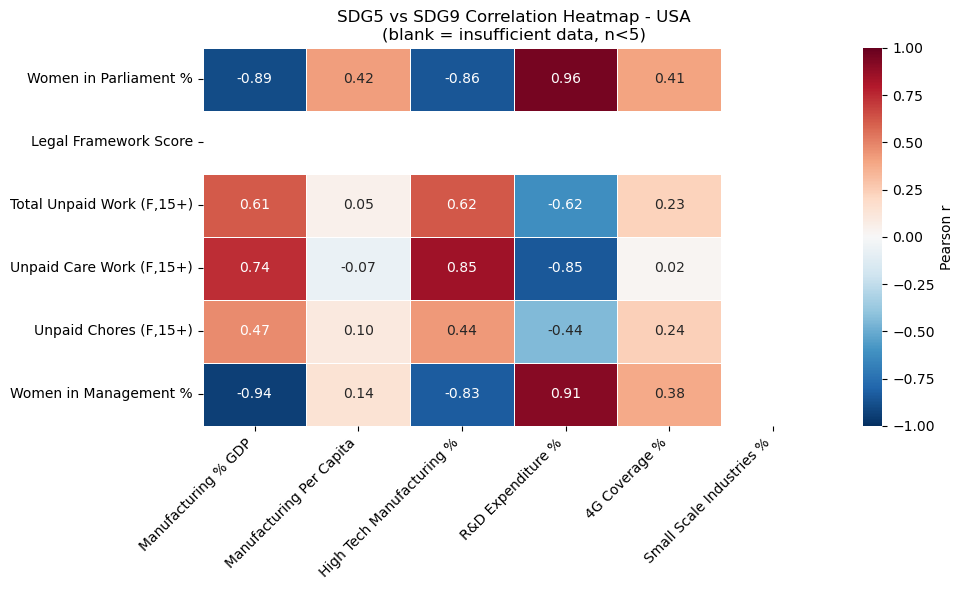

Saved: correlation_heatmap_USA.png


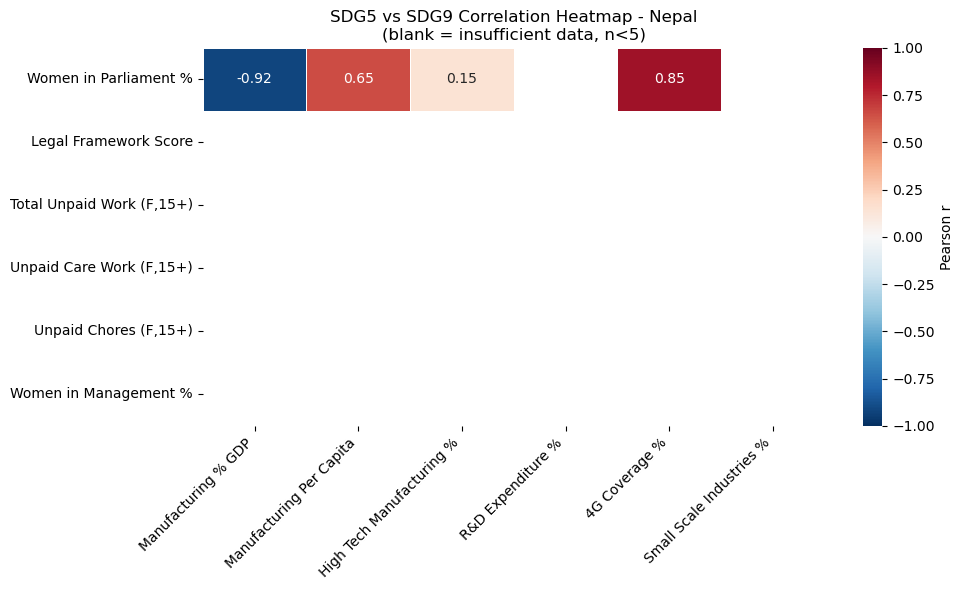

Saved: correlation_heatmap_Nepal.png


In [36]:
# ================================================
# CELL 17: CORRELATION HEATMAP
# Visualizes all r-values from Cell 16B as a color grid
# Low-data cells (n<5) are masked out so they don't
# visually compete with statistically reliable ones
# ================================================

import seaborn as sns              # the plotting library for the heatmap itself
import matplotlib.pyplot as plt     # needed to control figure size, save, etc.
import numpy as np                  # used for NaN handling

# Reuse the same SDG5 and SDG9 dictionaries from Cell 16B
# (if you're running this in the same notebook session, they already exist,
# but redefining here keeps this cell independent/safe to re-run)
sdg5 = {
    'SG_GEN_PARL':      ('Women in Parliament %', {}, {}),
    'SG_LGL_GENEQEMP':  ('Legal Framework Score', {}, {}),
    'SL_DOM_TSPD':      ('Total Unpaid Work (F,15+)', {'age':'15+'}, {'sex':'FEMALE'}),
    'SL_DOM_TSPDCW':    ('Unpaid Care Work (F,15+)', {'age':'15+'}, {'sex':'FEMALE'}),
    'SL_DOM_TSPDDC':    ('Unpaid Chores (F,15+)', {'age':'15+'}, {'sex':'FEMALE'}),
    'IC_GEN_MGTL':      ('Women in Management %', {}, {}),
}
sdg9 = {
    'NV_IND_MANF':    'Manufacturing % GDP',
    'NV_IND_MANFPC':  'Manufacturing Per Capita',
    'NV_IND_TECH':    'High Tech Manufacturing %',
    'GB_XPD_RSDV':    'R&D Expenditure %',
    'IT_MOB_4GNTWK':  '4G Coverage %',
    'NV_IND_SSIS':    'Small Scale Industries %',
}

# Loop through both countries and build one heatmap each
for country in ['United States of America', 'Nepal']:
    short = 'USA' if country == 'United States of America' else 'Nepal'

    # Empty grids: rows = SDG5 indicators, columns = SDG9 indicators
    # r_matrix holds the correlation coefficients
    # n_matrix holds how many overlapping years each pair had
    r_matrix = pd.DataFrame(index=[v[0] for v in sdg5.values()],
                             columns=list(sdg9.values()), dtype=float)
    n_matrix = pd.DataFrame(index=[v[0] for v in sdg5.values()],
                             columns=list(sdg9.values()), dtype=float)

    # Fill in both grids by looping through every SDG5 x SDG9 pair
    for s5_code, (s5_name, age_kw, sex_kw) in sdg5.items():
        s5 = get_series(country, s5_code, age=age_kw.get('age'), sex=sex_kw.get('sex'))
        for s9_code, s9_name in sdg9.items():
            s9 = get_series(country, s9_code)
            if s5.empty or s9.empty:
                continue
            merged = pd.merge(s5, s9, on='TimePeriod')
            n = len(merged)
            n_matrix.loc[s5_name, s9_name] = n
            # Only calculate and store r if we have at least 5 overlapping years
            if n >= 5:
                r, p = stats.pearsonr(merged[s5_code], merged[s9_code])
                r_matrix.loc[s5_name, s9_name] = r

    # Build a mask: True means "hide this cell" - either no data or n<5
    mask = n_matrix.isna() | (n_matrix < 5)

    # Draw the heatmap
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        r_matrix,           # the correlation values to color
        mask=mask,          # cells marked True here are left blank/grey
        annot=True,         # print the actual r-value inside each cell
        fmt='.2f',          # round displayed numbers to 2 decimals
        cmap='RdBu_r',      # red = negative, blue = positive correlation
        center=0,           # 0 correlation sits at the color midpoint
        vmin=-1, vmax=1,    # correlation always ranges -1 to 1
        linewidths=0.5,
        cbar_kws={'label': 'Pearson r'}
    )
    plt.title(f'SDG5 vs SDG9 Correlation Heatmap - {short}\n(blank = insufficient data, n<5)')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()

    # Save as PNG so you can use it in your presentation/Tableau writeup
    filename = f'correlation_heatmap_{short}.png'
    plt.savefig(filename, dpi=150)
    plt.show()

    print(f"Saved: {filename}")

In [37]:
# ================================================
# CELL 18: EDA FINDINGS
# 1. Exact year Nepal overtook USA in parliament %
# 2. Year-by-year comparison table
# 3. Which age/sex group carries the highest
#    domestic work burden in the USA
# ================================================

# --- PART 1: When did Nepal overtake the USA? ---

# Pull USA parliament % by year
usa_parl = combined_clean[
    (combined_clean['SeriesCode'] == 'SG_GEN_PARL') &
    (combined_clean['GeoAreaName'] == 'United States of America')
][['TimePeriod', 'Value']].rename(columns={'Value': 'USA'})

# Pull Nepal parliament % by year
nepal_parl = combined_clean[
    (combined_clean['SeriesCode'] == 'SG_GEN_PARL') &
    (combined_clean['GeoAreaName'] == 'Nepal')
][['TimePeriod', 'Value']].rename(columns={'Value': 'Nepal'})

# Merge on year so we can compare side by side, sorted oldest to newest
merged = pd.merge(usa_parl, nepal_parl, on='TimePeriod').sort_values('TimePeriod')

# New column: True if Nepal's % was higher than USA's that year
merged['Nepal_ahead'] = merged['Nepal'] > merged['USA']

# Print the full year-by-year table
print("=== Year-by-Year: Women in Parliament % ===")
print(merged.to_string(index=False))

# Filter to only years where Nepal was ahead, take the first one
overtake_years = merged[merged['Nepal_ahead']]
if len(overtake_years) > 0:
    first_year = overtake_years.iloc[0]['TimePeriod']
    print(f"\n>>> Nepal first overtook the USA in {first_year} <<<")
else:
    print("\nNepal never overtook the USA in the years we have data for")


# --- PART 2: Which age/sex group has the highest domestic work burden? ---

print("\n=== Average Unpaid Domestic Work by Age & Sex (USA) ===")

# Filter to just the USA rows for total unpaid domestic work
dom = combined_clean[
    (combined_clean['SeriesCode'] == 'SL_DOM_TSPD') &
    (combined_clean['GeoAreaName'] == 'United States of America')
]

# Group by age bracket and sex, average across all years,
# then sort so the highest burden appears first
avg_by_age_sex = dom.groupby(['Age', 'Sex'])['Value'].mean().sort_values(ascending=False)

print(avg_by_age_sex)

=== Year-by-Year: Women in Parliament % ===
 TimePeriod   USA  Nepal  Nepal_ahead
       2000 13.33   5.85        False
       2001 14.02   5.85        False
       2002 14.02   5.85        False
       2007 16.32  17.33         True
       2008 16.78  17.33         True
       2009 17.01  33.17         True
       2010 16.78  33.17         True
       2011 16.78  33.17         True
       2012 16.82  33.17         True
       2013 17.78  33.17         True
       2014 18.29  29.91         True
       2015 19.35  29.48         True
       2016 19.35  29.55         True
       2017 19.08  29.58         True
       2018 19.49  32.70         True
       2019 23.56  32.73         True
       2020 23.43  32.73         True
       2021 27.25  32.73         True
       2022 27.71  33.58         True
       2023 29.43  33.09         True
       2024 29.10  33.09         True
       2025 28.74  33.45         True

>>> Nepal first overtook the USA in 2007 <<<

=== Average Unpaid Domestic Work by